# 11 — Testing the fma_medium embeddings (EffNet + CLAP)

We just went from the 8,000-track fma_small catalogue to the 25,000-track
fma_medium one, with two embeddings per track:

| file | model | dims | used for |
|---|---|---:|---|
| `data/effnet_embeddings_medium.npz` | Discogs-EffNet (essentia) | 1280 | track-to-track similarity, the tiers |
| `data/clap_embeddings_medium.npz` | `laion/larger_clap_general` | 512 | text search ("jazz with saxophone") |

The EffNet file is stitched together from five runs (the old fma_small file plus
four parallel shards over the 17,000 new tracks), so on top of "is the file
well-formed" there is a real risk specific to this run: **a batch effect**,
where tracks embedded in one run cluster with each other instead of with
what they sound like. CLAP ran in a single pass and doubles as the control.

Every check goes through `check()`, which records PASS / FAIL and a short
detail line; the summary table at the end lists them all. Thresholds are set
from what the check is *for* (e.g. "3x chance"), not tuned to the results.

**Parts**

- **A. Integrity** — shapes, ids, finite values, coverage, fma_small rows unchanged
- **B. Reproducibility** — re-embed a handful of tracks from the audio and compare
- **C. Structure** — no collapse, no batch effect between runs/shards
- **D. Meaning** — genre agreement of neighbours, linear genre probe, bigger catalogue vs small
- **E. CLAP text search** — zero-shot genre, sub-genre queries, listening
- **F. EffNet vs CLAP** — do they find the same neighbours?
- **G. Web audio readiness** — does every catalogue track have a playable clip?
- **Summary**

Kernel: `tastebridge` (the main `.venv`, which has torch + transformers for
CLAP). The EffNet re-embedding in Part B shells out to `.venv-essentia`.

In [1]:
import sys
sys.path.append("..")

import ast
import subprocess
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

from modeling.data import load_tracks

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = REPO_ROOT / "data"
pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 160)

RESULTS = []


def check(part, name, passed, detail=""):
    # One row in the summary table; prints as it goes so a failure is visible in place.
    passed = bool(passed)
    RESULTS.append({"part": part, "check": name, "result": "PASS" if passed else "FAIL", "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f" -- {detail}" if detail else ""))


track_list = pd.read_csv(DATA / "processed" / "essentia_handoff" / "medium_all_tracks.csv", index_col=0).index
tracks = load_tracks("medium")
genre = tracks[("track", "genre_top")]
subset = tracks[("set", "subset")]  # "small" = the original 8k, "medium" = the 17k new ones

raw = {
    "effnet": np.load(DATA / "effnet_embeddings_medium.npz"),
    "clap": np.load(DATA / "clap_embeddings_medium.npz"),
}
small_ref = np.load(DATA / "effnet_embeddings_full.npz")  # the fma_small EffNet file the app runs on today
DIMS = {"effnet": 1280, "clap": 512}

for name, d in raw.items():
    print(f"{name:7s} ids {d['ids'].shape}  embeddings {d['embeddings'].shape} {d['embeddings'].dtype}")
print(f"track list: {len(track_list)} ids, metadata: {len(tracks)} tracks")

effnet  ids (24982,)  embeddings (24982, 1280) float32
clap    ids (24980,)  embeddings (24980, 512) float32
track list: 25000 ids, metadata: 25000 tracks


## A. Integrity

Structural checks on each file on its own — the same ones `modeling/merge_embeddings.py`
refuses to write without, re-run here on the files as they sit on disk now.

In [2]:
expected = set(track_list.tolist())
for name, d in raw.items():
    ids, emb = d["ids"], d["embeddings"]
    norms = np.linalg.norm(emb, axis=1)
    check("A", f"{name}: one row per id", len(ids) == len(emb), f"{len(ids)} ids, {len(emb)} rows")
    check("A", f"{name}: {DIMS[name]} dims, float32", emb.shape[1] == DIMS[name] and emb.dtype == np.float32,
          f"{emb.shape[1]} dims, {emb.dtype}")
    check("A", f"{name}: ids unique", len(np.unique(ids)) == len(ids), f"{len(ids) - len(np.unique(ids))} duplicates")
    check("A", f"{name}: ids sorted", (np.diff(ids) > 0).all())
    check("A", f"{name}: all values finite", np.isfinite(emb).all())
    check("A", f"{name}: no all-zero rows", (norms > 0).all(), f"min norm {norms.min():.3f}")
    stray = set(ids.tolist()) - expected
    check("A", f"{name}: every id is in fma_medium", not stray, f"{len(stray)} stray ids")

[PASS] effnet: one row per id -- 24982 ids, 24982 rows
[PASS] effnet: 1280 dims, float32 -- 1280 dims, float32
[PASS] effnet: ids unique -- 0 duplicates
[PASS] effnet: ids sorted
[PASS] effnet: all values finite
[PASS] effnet: no all-zero rows -- min norm 1.272
[PASS] effnet: every id is in fma_medium -- 0 stray ids
[PASS] clap: one row per id -- 24980 ids, 24980 rows
[PASS] clap: 512 dims, float32 -- 512 dims, float32
[PASS] clap: ids unique -- 0 duplicates
[PASS] clap: ids sorted
[PASS] clap: all values finite
[PASS] clap: no all-zero rows -- min norm 1.000
[PASS] clap: every id is in fma_medium -- 0 stray ids


**Coverage.** FMA ships a handful of truncated mp3s; those are expected to be
missing. The working catalogue for the app is the intersection of the two files.

In [3]:
missing = {name: sorted(expected - set(d["ids"].tolist())) for name, d in raw.items()}
for name, m in missing.items():
    check("A", f"{name}: coverage >= 99.8%", len(m) <= 0.002 * len(expected),
          f"{len(expected) - len(m)}/{len(expected)} embedded, missing {m}")

catalogue = np.intersect1d(raw["effnet"]["ids"], raw["clap"]["ids"])
only_effnet = np.setdiff1d(raw["effnet"]["ids"], raw["clap"]["ids"])
only_clap = np.setdiff1d(raw["clap"]["ids"], raw["effnet"]["ids"])
print(f"\ncatalogue (in both): {len(catalogue)}   only EffNet: {only_effnet.tolist()}   only CLAP: {only_clap.tolist()}")

missing_any = sorted(set(missing["effnet"]) | set(missing["clap"]) | set(only_effnet) | set(only_clap))
display(tracks.loc[missing_any, [("set", "subset"), ("artist", "name"), ("track", "title"), ("track", "genre_top")]])

[PASS] effnet: coverage >= 99.8% -- 24982/25000 embedded, missing [1486, 5574, 65753, 80391, 98558, 98559, 98560, 98565, 98567, 98569, 98571, 99134, 105247, 108925, 126981, 127336, 133297, 143992]
[PASS] clap: coverage >= 99.8% -- 24980/25000 embedded, missing [1486, 5574, 65753, 80391, 98558, 98559, 98560, 98565, 98566, 98567, 98568, 98569, 98571, 99134, 105247, 108925, 126981, 127336, 133297, 143992]

catalogue (in both): 24980   only EffNet: [98566, 98568]   only CLAP: []


set              artist                                track              
          subset                name                                title     genre_top
track_id                                                                               
1486      medium             Rainbro                             Greeting    Electronic
5574      medium     R. Stevie Moore                              Say Man          Rock
65753     medium                DJad                Keep Cool (Vocal Mix)    Electronic
80391     medium         A. P. Vague                                   a2  Instrumental
98558     medium              Hi-Rez                              Ex Girl       Hip-Hop
98559     medium              Hi-Rez                           Definition       Hip-Hop
98560     medium              Hi-Rez              Whats Love ft Kyle Dion       Hip-Hop
98565      small              Hi-Rez                        Brandon Clark       Hip-Hop
98566     medium              Hi-Rez                                 Poof       Hip-Hop
98567      small              Hi-Rez                       Fuck The World       Hip-Hop
98568     medium              Hi-Rez  Lifted ft Kyle Dion and Shizzy Sixx       Hip-Hop
98569      small              Hi-Rez                        Love and Fear       Hip-Hop
98571     medium              Hi-Rez        Jump Out The Window (Prod. Wh       Hip-Hop
99134      small     Pontic Firebird                                Halay    Electronic
105247    medium           Beme Seed           D Loop Jam (Demo-Fragment)          Rock
108925     small       Awkward Girls                       Epic Adventure          Rock
126981    medium            Vio/Mire                             Darkness          Folk
127336    medium        Andrew Howes                  Mounin c'est Facile          Rock
133297     small  Balog and Matthies                   (piano & mosesa7C)  Experimental
143992    medium            Hurry Up                           Go To Hell          Rock

From here on, both embeddings are restricted to that shared catalogue and put in
the same row order, so row *i* is the same track in both.

In [4]:
def aligned(name):
    d = raw[name]
    pos = pd.Series(np.arange(len(d["ids"])), index=d["ids"])
    return d["embeddings"][pos.loc[catalogue].to_numpy()]


E = {name: aligned(name) for name in raw}
U = {name: e / np.linalg.norm(e, axis=1, keepdims=True) for name, e in E.items()}  # unit rows: cosine = dot product
ids = catalogue
row = pd.Series(np.arange(len(ids)), index=ids)
g = genre.loc[ids].to_numpy()
is_new = (subset.loc[ids] == "medium").to_numpy()
print(f"{len(ids)} tracks: {(~is_new).sum()} from fma_small, {is_new.sum()} new in fma_medium; "
      f"{pd.isna(g).sum()} without a top genre")

24980 tracks: 7994 from fma_small, 16986 new in fma_medium; 0 without a top genre


**Norms.** `clap_embed.embed_file` writes unit-length vectors. EffNet vectors
are not normalised (the recommender uses cosine, so magnitude is ignored), but a
handful of wildly off norms would point at a broken decode.

In [5]:
clap_norm = np.linalg.norm(E["clap"], axis=1)
check("A", "clap: unit-length rows", np.abs(clap_norm - 1).max() < 1e-3, f"max |norm - 1| = {np.abs(clap_norm - 1).max():.2e}")

eff_norm = pd.Series(np.linalg.norm(E["effnet"], axis=1), index=ids)
z = (eff_norm - eff_norm.median()) / (eff_norm.quantile(0.75) - eff_norm.quantile(0.25))
print(eff_norm.describe().round(3).to_string())
check("A", "effnet: no extreme norm outliers (|robust z| < 10)", (z.abs() < 10).all(),
      f"{(z.abs() >= 10).sum()} outliers; small mean {eff_norm[~is_new].mean():.3f} vs new mean {eff_norm[is_new].mean():.3f}")

[PASS] clap: unit-length rows -- max |norm - 1| = 1.19e-07


count    24980.000
mean         3.206
std          0.955
min          1.272
25%          2.556
50%          3.050
75%          3.652
max         12.483
[PASS] effnet: no extreme norm outliers (|robust z| < 10) -- 0 outliers; small mean 3.030 vs new mean 3.289


**fma_small rows unchanged.** The 7,994 fma_small rows in the merged EffNet
file should be byte-identical to `effnet_embeddings_full.npz`, the file the app
and notebooks 08–10 were built on. If this holds, every earlier result on
fma_small still applies to these vectors.

In [6]:
ref_ids, ref_emb = small_ref["ids"], small_ref["embeddings"]
med_pos = pd.Series(np.arange(len(raw["effnet"]["ids"])), index=raw["effnet"]["ids"])
in_merged = np.isin(ref_ids, raw["effnet"]["ids"])
check("A", "effnet: every fma_small id carried over", in_merged.all(), f"{in_merged.sum()}/{len(ref_ids)}")
same = np.array_equal(raw["effnet"]["embeddings"][med_pos.loc[ref_ids[in_merged]].to_numpy()], ref_emb[in_merged])
check("A", "effnet: fma_small rows identical to effnet_embeddings_full.npz", same)

[PASS] effnet: every fma_small id carried over -- 7994/7994
[PASS] effnet: fma_small rows identical to effnet_embeddings_full.npz


## B. Reproducibility — re-embed from the audio

Pick tracks at random (half fma_small, half new; for EffNet one from each
shard), run them through the same embedding code again, and compare to what is
stored. This catches row/id misalignment, which no structural check can:
a file with every vector shifted by one row would pass all of Part A.

Threshold is cosine ≥ 0.99 rather than exact equality — Apple's GPU (MPS) and
TensorFlow are not bit-deterministic.

In [7]:
rng = np.random.default_rng(11)
shard_of = pd.Series(-1, index=ids)  # -1 = fma_small file; 0-3 = which EffNet shard embedded the track
for s in range(4):
    shard_ids = np.load(DATA / "embeddings_partial" / f"effnet_medium_shard{s}.npz")["ids"]
    shard_of.loc[np.intersect1d(shard_ids, ids)] = s

spot = np.concatenate([rng.choice(ids[shard_of.to_numpy() == s], size=3 if s == -1 else 2, replace=False)
                       for s in [-1, 0, 1, 2, 3]])
display(pd.DataFrame({"shard": shard_of.loc[spot].values, "genre": genre.loc[spot].values,
                      "artist": tracks.loc[spot, ("artist", "name")].values,
                      "title": tracks.loc[spot, ("track", "title")].values}, index=spot))

,shard,genre,artist,title
26301,-1,Experimental,Karl Blau,The Dance Of The Sugar Plumb Fairy
126490,-1,Folk,Nate Maingard,Just Like You
25216,-1,International,Zlatne Uste Balkan Brass Band,Kolo Iz Sumadije
109080,0,Rock,Kraus,Workers in Control
87372,0,Electronic,Bing Satellites,Motif One
19724,1,Rock,Fresh Body Shop,One More Reason
68532,1,Hip-Hop,Tha Silent Partner,IDKWHUTEYEJUSDIDLOL
76395,2,Electronic,Organoid,Distance
141121,2,Hip-Hop,dustmotes,Soulbox
75778,3,Electronic,Electric Children,Car-Jack (2011 Version)


In [8]:
from modeling import clap_embed

t0 = time.time()
fresh = np.vstack([clap_embed.embed_file(clap_embed.audio_path(t)) for t in spot])
cos = (fresh * U["clap"][row.loc[spot]]).sum(axis=1)
print(pd.Series(cos.round(5), index=spot).to_string(), f"\n({time.time() - t0:.0f}s)")
check("B", f"clap: {len(spot)} re-embedded tracks match stored (cos >= 0.99)", (cos >= 0.99).all(),
      f"min cos {cos.min():.5f}")

# Wrong-row control: each fresh vector against the *other* spot tracks' stored rows.
others = fresh @ U["clap"][row.loc[spot]].T
off_diag = others[~np.eye(len(spot), dtype=bool)]
print(f"control -- same vectors vs other tracks' rows: max cos {off_diag.max():.3f}")

Loading weights:   0%|          | 0/555 [00:00<?, ?it/s]

26301     1.0
126490    1.0
25216     1.0
109080    1.0
87372     1.0
19724     1.0
68532     1.0
76395     1.0
141121    1.0
75778     1.0
17707     1.0 
(8s)
[PASS] clap: 11 re-embedded tracks match stored (cos >= 0.99) -- min cos 1.00000
control -- same vectors vs other tracks' rows: max cos 0.700


In [9]:
ESSENTIA_PY = REPO_ROOT / ".venv-essentia" / "bin" / "python"

if not ESSENTIA_PY.exists():
    check("B", "effnet: re-embedded tracks match stored", False, ".venv-essentia not found -- skipped")
else:
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        pd.DataFrame(index=pd.Index(spot, name="track_id")).to_csv(tmp / "spot.csv")
        t0 = time.time()
        proc = subprocess.run(
            [str(ESSENTIA_PY), "-m", "modeling.essentia_embed", "--track-list", str(tmp / "spot.csv"),
             "--out", str(tmp / "spot.npz"), "--audio-dir", str(DATA / "fma_medium"), "--no-resume"],
            cwd=REPO_ROOT, capture_output=True, text=True,
        )
        if proc.returncode != 0:
            print(proc.stderr[-2000:])
        out = np.load(tmp / "spot.npz")
    fresh_ids, fresh_emb = out["ids"], out["embeddings"]
    fresh_u = fresh_emb / np.linalg.norm(fresh_emb, axis=1, keepdims=True)
    cos = (fresh_u * U["effnet"][row.loc[fresh_ids]]).sum(axis=1)
    print(pd.DataFrame({"shard": shard_of.loc[fresh_ids].values, "cos": cos.round(5)}, index=fresh_ids).to_string(),
          f"\n({time.time() - t0:.0f}s)")
    check("B", f"effnet: {len(spot)} re-embedded tracks match stored (cos >= 0.99)",
          len(fresh_ids) == len(spot) and (cos >= 0.99).all(), f"min cos {cos.min():.5f}, {len(fresh_ids)} returned")
    others = fresh_u @ U["effnet"][row.loc[fresh_ids]].T
    print(f"control -- same vectors vs other tracks' rows: max cos {others[~np.eye(len(fresh_ids), dtype=bool)].max():.3f}")

        shard  cos
26301      -1  1.0
126490     -1  1.0
25216      -1  1.0
109080      0  1.0
87372       0  1.0
19724       1  1.0
68532       1  1.0
76395       2  1.0
141121      2  1.0
75778       3  1.0
17707       3  1.0 
(8s)
[PASS] effnet: 11 re-embedded tracks match stored (cos >= 0.99) -- min cos 1.00000, 11 returned
control -- same vectors vs other tracks' rows: max cos 0.662


## C. Structure — collapse and batch effects

First, one shared computation: the 10 nearest neighbours (cosine) of every
track in each space, over the full 25k catalogue. Parts C, D and F all read
from it.

In [10]:
K = 10


def knn(u, k=K, chunk=2000):
    # Top-k neighbours of every row by cosine, excluding itself. Returns (idx, sims), both (n, k).
    n = len(u)
    idx, sims = np.empty((n, k), dtype=np.int64), np.empty((n, k), dtype=np.float32)
    for a in range(0, n, chunk):
        s = u[a:a + chunk] @ u.T
        s[np.arange(len(s)), np.arange(a, a + len(s))] = -np.inf
        part = np.argpartition(-s, k, axis=1)[:, :k]
        ps = np.take_along_axis(s, part, axis=1)
        order = np.argsort(-ps, axis=1)
        idx[a:a + chunk], sims[a:a + chunk] = np.take_along_axis(part, order, axis=1), np.take_along_axis(ps, order, axis=1)
    return idx, sims


t0 = time.time()
NN = {name: knn(u) for name, u in U.items()}
print(f"kNN for both spaces in {time.time() - t0:.0f}s")

kNN for both spaces in 9s


**Collapse.** The failure we already hit once (`larger_clap_music`, see the
docstring of `modeling/clap_embed.py`): every track maps to nearly the same
vector, cosine ≈ 0.95 between *any* two tracks. Tests:

- a track's nearest neighbour should be clearly closer than a random track (median gap ≥ 0.1)
- the space should use more than a few directions: ≥ 10 principal components to reach 90% of the variance

[PASS] effnet: neighbours clearly closer than random pairs -- median NN cos 0.849 vs random 0.353
[PASS] effnet: not collapsed (>= 10 PCs for 90% variance) -- 365 PCs
[PASS] clap: neighbours clearly closer than random pairs -- median NN cos 0.877 vs random 0.318
[PASS] clap: not collapsed (>= 10 PCs for 90% variance) -- 51 PCs


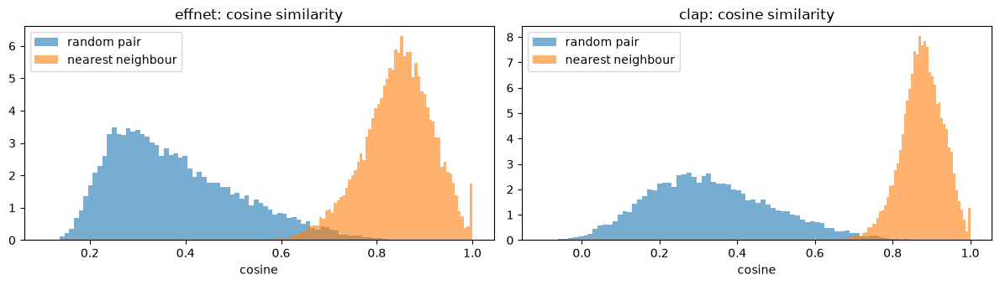

In [11]:
pairs = rng.integers(0, len(ids), size=(20000, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (name, u) in zip(axes, U.items()):
    rand_cos = (u[pairs[:, 0]] * u[pairs[:, 1]]).sum(axis=1)
    nn_cos = NN[name][1][:, 0]
    centred = u - u.mean(axis=0)
    var = np.linalg.svd(centred[rng.choice(len(u), 5000, replace=False)], compute_uv=False) ** 2
    dims90 = int(np.searchsorted(np.cumsum(var) / var.sum(), 0.9) + 1)
    gap = np.median(nn_cos) - np.median(rand_cos)
    check("C", f"{name}: neighbours clearly closer than random pairs", gap >= 0.1,
          f"median NN cos {np.median(nn_cos):.3f} vs random {np.median(rand_cos):.3f}")
    check("C", f"{name}: not collapsed (>= 10 PCs for 90% variance)", dims90 >= 10, f"{dims90} PCs")
    ax.hist(rand_cos, bins=80, alpha=0.6, density=True, label="random pair")
    ax.hist(nn_cos, bins=80, alpha=0.6, density=True, label="nearest neighbour")
    ax.set(title=f"{name}: cosine similarity", xlabel="cosine")
    ax.legend()
plt.tight_layout()
plt.show()

**Near-duplicates.** FMA is known to contain re-uploads of the same track under
different ids. A few are fine — they're real duplicates, and the app should
probably hide them from each other's recommendations — but thousands would
mean many tracks got the same vector by mistake.

In [12]:
DUP_COS = 0.999
dup_rows = {}
for name in U:
    nn_idx, nn_sim = NN[name]
    hit = np.flatnonzero(nn_sim[:, 0] >= DUP_COS)
    dup_rows[name] = hit
    check("C", f"{name}: near-duplicate vectors < 1% of tracks", len(hit) < 0.01 * len(ids),
          f"{len(hit)} tracks have a neighbour at cos >= {DUP_COS}")

both = np.intersect1d(dup_rows["effnet"], dup_rows["clap"])
print(f"\n{len(both)} tracks are near-duplicates in BOTH spaces (most likely genuine re-uploads). Examples:")
nn_idx = NN["effnet"][0]
pairs_df = pd.DataFrame([
    {"track": ids[i], "artist": tracks.loc[ids[i], ("artist", "name")], "title": tracks.loc[ids[i], ("track", "title")],
     "dup_of": ids[nn_idx[i, 0]], "dup_artist": tracks.loc[ids[nn_idx[i, 0]], ("artist", "name")],
     "dup_title": tracks.loc[ids[nn_idx[i, 0]], ("track", "title")]}
    for i in both[:12]
])
display(pairs_df)

[PASS] effnet: near-duplicate vectors < 1% of tracks -- 197 tracks have a neighbour at cos >= 0.999
[PASS] clap: near-duplicate vectors < 1% of tracks -- 167 tracks have a neighbour at cos >= 0.999

165 tracks are near-duplicates in BOTH spaces (most likely genuine re-uploads). Examples:


,track,artist,title,dup_of,dup_artist,dup_title
0,7764,junior85,03 (hometown).mp3,95409,junior85,(hometown)
1,25928,"Sasha Cooke, mezzo-soprano; Pei-Yao Wang, piano",Claude Debussy: Chansons de Bilitis,46648,"Sasha Cooke, mezzo-soprano; Pei-Yao Wang, piano",Chansons de Bilitis (Claude Debussy)
2,30738,environmental sound collapse,chiptune is as dead as gabe's mom,55776,environmental sound collapse,chiptune is as dead as gabe's mom
3,33200,El Haijn,Out Of The Unknown,40370,El Haijn,Out Of The Unknown
4,36802,Rully Shabara & Wukir,Warna,41752,Rully Shabara & Wukir,Warna
5,38955,Liam Stewart,Bird Of Prey,39530,Liam Stewart,Bird Of Prey (Album Version)
6,39530,Liam Stewart,Bird Of Prey (Album Version),38955,Liam Stewart,Bird Of Prey
7,40351,A.L.I.C.E,Kontradiksi Tirani,41809,A.L.I.C.E,Kontradiksi Tirani
8,40370,El Haijn,Out Of The Unknown,33200,El Haijn,Out Of The Unknown
9,40541,uiutna,kiss of halloween,40542,uiutna,kiss of halloween instrumental


**Batch effect between runs.** If the fma_small run and the four new shards
embedded audio slightly differently (different library version, different
decoder, a resampling difference), tracks would prefer neighbours *from their
own run*. That would be invisible in Part A and devastating in the app: an
fma_small seed would almost never be recommended a new track.

Test: for each seed, what fraction of its 10 neighbours come from the *other*
group (small ↔ new), against what you'd expect if group didn't matter —
the other group's share *within the seed's genre* (the two groups have very
different genre mixes: fma_small is balanced, the new 17k are mostly Rock and
Electronic). A ratio near 1 = perfectly mixed; near 0 = segregated.
CLAP ran in one pass over all 25k, so its ratio is the control: whatever
mixing CLAP shows is "natural" for these two groups.

In [13]:
genre_counts = pd.crosstab(g, is_new)  # rows genre, cols False (small) / True (new)


def mixing(name):
    nn_idx = NN[name][0]
    other = is_new[nn_idx] != is_new[:, None]
    observed = other.mean(axis=1)
    n_new = genre_counts.loc[g, True].to_numpy()
    n_small = genre_counts.loc[g, False].to_numpy()
    n_all = n_new + n_small - 1  # excluding the seed
    expected = np.where(is_new, n_small, n_new) / n_all
    return pd.DataFrame({
        "group": np.where(is_new, "new seeds", "small seeds"), "observed": observed, "expected": expected,
    }).groupby("group").mean().assign(ratio=lambda d: d.observed / d.expected)


mix = pd.concat({name: mixing(name) for name in U}, names=["space"]).round(3)
display(mix)
for grp in ["small seeds", "new seeds"]:
    r_eff, r_clap = mix.loc[("effnet", grp), "ratio"], mix.loc[("clap", grp), "ratio"]
    check("C", f"effnet: no small/new batch effect ({grp})", r_eff >= 0.5 and r_eff >= 0.75 * r_clap,
          f"cross-group ratio {r_eff:.2f} (CLAP control {r_clap:.2f})")

observed  expected  ratio
space  group                                 
effnet new seeds       0.226     0.210  1.074
       small seeds     0.555     0.447  1.242
clap   new seeds       0.235     0.210  1.118
       small seeds     0.518     0.447  1.159

[PASS] effnet: no small/new batch effect (small seeds) -- cross-group ratio 1.24 (CLAP control 1.16)
[PASS] effnet: no small/new batch effect (new seeds) -- cross-group ratio 1.07 (CLAP control 1.12)


**Batch effect between the four EffNet shards.** Same idea, one level down:
among a new track's neighbours that are also new, how many come from the
*same* shard? The shards are every 4th id, so with no batch effect that should
be ~25%.

In [14]:
shard = shard_of.loc[ids].to_numpy()
nn_idx = NN["effnet"][0]
rows_ = []
for s in range(4):
    seeds = np.flatnonzero(shard == s)
    nb = shard[nn_idx[seeds]]
    nb_new = nb >= 0
    same = ((nb == s) & nb_new).sum() / nb_new.sum()
    rows_.append({"shard": s, "tracks": len(seeds), "same-shard share of new neighbours": same,
                  "expected": (shard == s).sum() / (shard >= 0).sum()})
shard_df = pd.DataFrame(rows_).set_index("shard").round(3)
display(shard_df)
worst = (shard_df["same-shard share of new neighbours"] - shard_df["expected"]).abs().max()
check("C", "effnet: no batch effect between the 4 shards", worst < 0.05, f"max deviation from expected {worst:.3f}")

,tracks,same-shard share of new neighbours,expected
shard,,,
0,4246,0.227,0.25
1,4246,0.231,0.25
2,4246,0.233,0.25
3,4248,0.227,0.25


[PASS] effnet: no batch effect between the 4 shards -- max deviation from expected 0.023


## D. Meaning — do neighbours share a genre?

Genre is a coarse proxy for "sounds similar", but it's the only label all 25k
tracks have, and it's what notebooks 06–08 used, so the numbers are
comparable. **Genre agreement@10** = share of a track's 10 neighbours with the
same top genre. **Chance** = that genre's share of the catalogue — what random
recommendations would score. **Lift** = agreement / chance.

In [15]:
def agreement_table(name):
    nn_idx = NN[name][0]
    agree = (g[nn_idx] == g[:, None]).mean(axis=1)
    df = pd.DataFrame({"genre": g, "agree": agree}).groupby("genre").agg(tracks=("agree", "size"), agreement=("agree", "mean"))
    df["chance"] = (df["tracks"] - 1) / (len(ids) - 1)
    df["lift"] = df["agreement"] / df["chance"]
    return df


agree = pd.concat({name: agreement_table(name) for name in U}, axis=1)
agree = agree.sort_values(("effnet", "tracks"), ascending=False)
display(agree.round(3))

for name in U:
    a = agree[name]
    micro = (a["agreement"] * a["tracks"]).sum() / a["tracks"].sum()
    micro_chance = (a["chance"] * a["tracks"]).sum() / a["tracks"].sum()
    big = a[a["tracks"] >= 50]
    check("D", f"{name}: agreement@10 >= 2x chance overall", micro >= 2 * micro_chance,
          f"{micro:.3f} vs chance {micro_chance:.3f} (macro {a['agreement'].mean():.3f})")
    check("D", f"{name}: beats chance in every genre with >= 50 tracks", (big["lift"] > 1).all(),
          f"lowest lift {big['lift'].min():.2f} ({big['lift'].idxmin()})")

effnet                            clap                         
                    tracks agreement chance    lift tracks agreement chance    lift
genre                                                                              
Rock                  7098     0.818  0.284   2.881   7098     0.814  0.284   2.865
Electronic            6311     0.759  0.253   3.004   6311     0.768  0.253   3.041
Experimental          2250     0.414  0.090   4.593   2250     0.401  0.090   4.454
Hip-Hop               2192     0.740  0.088   8.432   2192     0.774  0.088   8.826
Folk                  1518     0.587  0.061   9.666   1518     0.627  0.061  10.317
Instrumental          1349     0.392  0.054   7.262   1349     0.482  0.054   8.926
Pop                   1186     0.177  0.047   3.738   1186     0.241  0.047   5.085
International         1018     0.626  0.041  15.364   1018     0.690  0.041  16.940
Classical              619     0.844  0.025  34.098    619     0.861  0.025  34.804
Old-Time / Historic    510     0.984  0.020  48.286    510     0.985  0.020  48.353
Jazz                   384     0.507  0.015  33.068    384     0.508  0.015  33.153
Country                178     0.570  0.007  80.393    178     0.508  0.007  71.751
Soul-RnB               154     0.311  0.006  50.781    154     0.309  0.006  50.463
Spoken                 118     0.435  0.005  92.816    118     0.426  0.005  91.007
Blues                   74     0.245  0.003  83.695     74     0.239  0.003  81.845
Easy Listening          21     0.062  0.001  77.316     21     0.067  0.001  83.263

[PASS] effnet: agreement@10 >= 2x chance overall -- 0.675 vs chance 0.172 (macro 0.529)
[PASS] effnet: beats chance in every genre with >= 50 tracks -- lowest lift 2.88 (Rock)
[PASS] clap: agreement@10 >= 2x chance overall -- 0.691 vs chance 0.172 (macro 0.544)
[PASS] clap: beats chance in every genre with >= 50 tracks -- lowest lift 2.87 (Rock)


**Did the bigger catalogue hurt?** Same seeds (the fma_small tracks), same
EffNet vectors (Part A showed they're identical), two catalogues to search: the
old 8k and the new 25k. More candidates should mean neighbours at least as
close, and similar or better genre agreement — unless the new tracks are
noisy enough to crowd out good matches.

In [16]:
small_rows = np.flatnonzero(~is_new)
rows_ = []
for name in U:
    nn_small_idx, nn_small_sim = knn(U[name][small_rows])
    a_small = (g[small_rows][nn_small_idx] == g[small_rows][:, None]).mean(axis=1)
    a_med = (g[NN[name][0][small_rows]] == g[small_rows][:, None]).mean(axis=1)
    by_genre = pd.DataFrame({"genre": g[small_rows], "small_8k": a_small, "medium_25k": a_med}).groupby("genre").mean()
    rows_.append(by_genre.assign(space=name))
    check("D", f"{name}: fma_small seeds agree as well in the 25k catalogue (macro drop <= 0.05)",
          by_genre["medium_25k"].mean() >= by_genre["small_8k"].mean() - 0.05,
          f"8k {by_genre['small_8k'].mean():.3f} -> 25k {by_genre['medium_25k'].mean():.3f}; "
          f"mean NN cos {nn_small_sim[:, 0].mean():.3f} -> {NN[name][1][small_rows, 0].mean():.3f}")
display(pd.concat(rows_).reset_index().pivot(index="genre", columns="space", values=["small_8k", "medium_25k"]).round(3))

[PASS] effnet: fma_small seeds agree as well in the 25k catalogue (macro drop <= 0.05) -- 8k 0.592 -> 25k 0.566; mean NN cos 0.814 -> 0.829


[PASS] clap: fma_small seeds agree as well in the 25k catalogue (macro drop <= 0.05) -- 8k 0.627 -> 25k 0.599; mean NN cos 0.856 -> 0.870


small_8k        medium_25k       
space             clap effnet       clap effnet
genre                                          
Electronic       0.662  0.643      0.803  0.802
Experimental     0.433  0.454      0.384  0.396
Folk             0.668  0.626      0.626  0.582
Hip-Hop          0.799  0.780      0.747  0.722
Instrumental     0.640  0.566      0.509  0.419
International    0.786  0.715      0.688  0.623
Pop              0.388  0.310      0.245  0.183
Rock             0.638  0.639      0.787  0.798

**Linear genre probe.** A stricter test of how much genre information the
vectors carry: a plain logistic regression from embedding to top genre,
trained on FMA's own `training`+`validation` split and scored on `test`.
Balanced accuracy, so the 7,000 Rock tracks don't carry the score; chance is
1/16. Pass = 3× chance.

In [17]:
split = tracks.loc[ids, ("set", "split")].to_numpy()
train, test = split != "test", split == "test"
probe = {}
for name, e in E.items():
    t0 = time.time()
    scaler = StandardScaler().fit(e[train])
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.1)
    clf.fit(scaler.transform(e[train]), g[train])
    pred = clf.predict(scaler.transform(e[test]))
    probe[name] = pd.Series(f1_score(g[test], pred, average=None, labels=clf.classes_), index=clf.classes_)
    bacc = balanced_accuracy_score(g[test], pred)
    check("D", f"{name}: linear genre probe >= 3x chance (balanced acc)", bacc >= 3 / 16,
          f"balanced acc {bacc:.3f} vs chance {1/16:.3f}, accuracy {(pred == g[test]).mean():.3f} ({time.time() - t0:.0f}s)")
display(pd.DataFrame(probe).assign(test_tracks=pd.Series(g[test]).value_counts()).sort_values("test_tracks", ascending=False).round(2))

[PASS] effnet: linear genre probe >= 3x chance (balanced acc) -- balanced acc 0.462 vs chance 0.062, accuracy 0.610 (2s)


[PASS] clap: linear genre probe >= 3x chance (balanced acc) -- balanced acc 0.558 vs chance 0.062, accuracy 0.643 (1s)


,effnet,clap,test_tracks
Rock,0.79,0.80,710
Electronic,0.74,0.81,632
Experimental,0.40,0.43,225
Hip-Hop,0.79,0.79,220
Instrumental,0.26,0.25,174
Folk,0.39,0.36,152
Pop,0.21,0.29,119
International,0.54,0.69,102
Classical,0.84,0.88,62
Old-Time / Historic,0.97,0.99,51


## E. CLAP text search

This is what CLAP is for. At query time only the text tower runs:
`embed_text([query]) @ clap_embeddings.T`, one dot product per track.

**Zero-shot genre.** Embed one prompt per genre ("Hip-Hop music"), give each
track the genre whose prompt it's closest to. Our checkpoint benchmark got
0.79 on 6 well-separated genres; 16 genres including "Experimental",
"International" and "Instrumental" is much harder, so the bar is 3× chance.

[PASS] clap: zero-shot genre from text >= 3x chance (balanced acc) -- balanced acc 0.404, accuracy 0.435


,Jazz,Classical,Electronic,Hip-Hop,Rock,International,Folk,Instrumental,Country,Pop,Soul-RnB,Spoken,Blues,Easy Listening,Experimental,Old-Time / Historic
P@20,1.00,0.95,0.90,0.90,0.90,0.65,0.50,0.40,0.25,0.20,0.05,0.05,0.0,0.0,0.00,0.00
base rate,0.02,0.02,0.25,0.09,0.28,0.04,0.06,0.05,0.01,0.05,0.01,0.00,0.0,0.0,0.09,0.02


[PASS] clap: genre prompts P@20 beat the base rate on average -- mean P@20 0.42 vs mean base rate 0.06


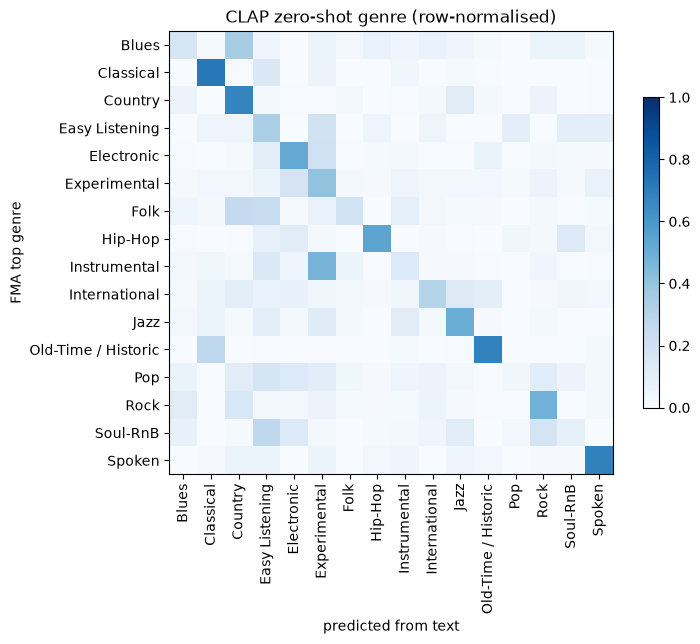

In [18]:
genres = sorted(pd.unique(g))
prompts = [f"{x} music" for x in genres]
T = clap_embed.embed_text(prompts)
T = T / np.linalg.norm(T, axis=1, keepdims=True)
scores = U["clap"] @ T.T
zs_pred = np.array(genres)[scores.argmax(axis=1)]
bacc = balanced_accuracy_score(g, zs_pred)
check("E", "clap: zero-shot genre from text >= 3x chance (balanced acc)", bacc >= 3 / 16,
      f"balanced acc {bacc:.3f}, accuracy {(zs_pred == g).mean():.3f}")

# Retrieval view: for each genre prompt, how many of the top 20 tracks have that genre?
p20 = pd.Series({x: (g[np.argsort(-scores[:, j])[:20]] == x).mean() for j, x in enumerate(genres)}, name="P@20")
base = pd.Series(g).value_counts(normalize=True).rename("base rate")
display(pd.concat([p20, base], axis=1).sort_values("P@20", ascending=False).round(2).T)
check("E", "clap: genre prompts P@20 beat the base rate on average", (p20 - base.loc[p20.index]).mean() > 0.2,
      f"mean P@20 {p20.mean():.2f} vs mean base rate {base.loc[p20.index].mean():.2f}")

conf = pd.crosstab(pd.Series(g, name="true"), pd.Series(zs_pred, name="predicted"), normalize="index")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(conf.reindex(index=genres, columns=genres, fill_value=0), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(genres)), genres, rotation=90)
ax.set_yticks(range(len(genres)), genres)
ax.set(title="CLAP zero-shot genre (row-normalised)", xlabel="predicted from text", ylabel="FMA top genre")
fig.colorbar(im, shrink=0.7)
plt.tight_layout()
plt.show()

**Sub-genre and descriptive queries.** Closer to what a user would type. FMA
tags tracks with fine-grained genres (`genres_all` includes every ancestor), so
for queries that map onto one of those tags we can score the top 20 results
against it. **Lift** = P@20 / the tag's share of the catalogue.

In [19]:
genre_titles = pd.read_csv(DATA / "fma_metadata" / "genres.csv", index_col=0)["title"]
gid = {t: i for i, t in genre_titles.items()}
genres_all = tracks.loc[ids, ("track", "genres_all")].map(ast.literal_eval)

QUERIES = {
    "ambient drone soundscape": "Ambient",
    "8-bit chiptune video game music": "Chiptune",
    "fast drum and bass with breakbeats": "Drum & Bass",
    "dubstep with heavy wobble bass": "Dubstep",
    "heavy metal with distorted guitars and screaming vocals": "Metal",
    "fast loud punk rock": "Punk",
    "harsh noise": "Noise",
    "a man reading a poem": "Poetry",
    "banjo and fiddle bluegrass": "Bluegrass",
    "opera singer with orchestra": "Opera",
    "minimal techno": "Techno",
    "surf rock with twangy reverb guitar": "Surf",
    "field recording of birds and nature sounds": "Field Recordings",
    "jazz with saxophone and swing drums": "Jazz",
}
Q = clap_embed.embed_text(list(QUERIES))
Q = Q / np.linalg.norm(Q, axis=1, keepdims=True)
qscores = U["clap"] @ Q.T
rows_ = []
for j, (q, tag) in enumerate(QUERIES.items()):
    has_tag = genres_all.map(lambda gs: gid[tag] in gs).to_numpy()
    top = np.argsort(-qscores[:, j])[:20]
    rows_.append({"query": q, "tag": tag, "P@20": has_tag[top].mean(), "base rate": has_tag.mean(),
                  "lift": has_tag[top].mean() / has_tag.mean()})
qdf = pd.DataFrame(rows_).set_index("query").round(3)
display(qdf)
check("E", "clap: >= 10 of 14 descriptive queries reach 5x lift", (qdf["lift"] >= 5).sum() >= 10,
      f"{(qdf['lift'] >= 5).sum()}/14, median P@20 {qdf['P@20'].median():.2f}")

,tag,P@20,base rate,lift
query,,,,
ambient drone soundscape,Ambient,0.40,0.016,24.611
8-bit chiptune video game music,Chiptune,0.70,0.028,25.196
fast drum and bass with breakbeats,Drum & Bass,0.65,0.009,74.482
dubstep with heavy wobble bass,Dubstep,0.65,0.023,28.140
heavy metal with distorted guitars and screaming vocals,Metal,0.65,0.023,28.140
fast loud punk rock,Punk,0.85,0.133,6.401
harsh noise,Noise,0.10,0.019,5.129
a man reading a poem,Poetry,0.10,0.001,71.371
banjo and fiddle bluegrass,Bluegrass,0.20,0.001,192.154


[PASS] clap: >= 10 of 14 descriptive queries reach 5x lift -- 14/14, median P@20 0.50


**Listen.** Numbers say whether the labels line up; only ears say whether the
results *sound* right — especially for queries with no matching tag. Clips come
from `data/web_audio` (the 128 kbps, loudness-matched versions the app will
serve). Set `LISTEN = False` to skip embedding audio in the notebook.

In [20]:
LISTEN = True
WEB_AUDIO = DATA / "web_audio"


def web_clip(track_id):
    name = f"{int(track_id):06d}"
    return WEB_AUDIO / name[:3] / f"{name}.mp3"


def describe(track_id):
    m = tracks.loc[track_id]
    return f"{track_id}  {m[('artist', 'name')]} -- {m[('track', 'title')]}  [{m[('track', 'genre_top')]}]"


def play(track_id, prefix=""):
    print(prefix + describe(track_id))
    if LISTEN:
        display(Audio(filename=str(web_clip(track_id))))


def text_search(query, n=3):
    q = clap_embed.embed_text([query])
    q = q / np.linalg.norm(q)
    s = U["clap"] @ q[0]
    top = np.argsort(-s)[:n]
    print(f'\n=== "{query}" ===')
    for i in top:
        play(ids[i], f"  cos {s[i]:.3f}  ")


for query in ["dreamy female vocals with acoustic guitar",
              "aggressive rap over a hard boom bap beat",
              "slow sad piano"]:
    text_search(query)


=== "dreamy female vocals with acoustic guitar" ===
  cos 0.376  64992  Action Davis -- Lights - And Counting (Action Davis Remix)  [Hip-Hop]


  cos 0.352  147300  Vienna Ditto -- A Wheel WIthin a Wheel  [Electronic]


  cos 0.349  3271  Arborea -- Beirut  [Folk]



=== "aggressive rap over a hard boom bap beat" ===
  cos 0.449  89846  Not The 1s -- Fly as Fuck feat. Isaiah Toothtaker (prod. by Young L)  [Hip-Hop]


  cos 0.446  149370  K.I.R.K -- Glorious  [Hip-Hop]


  cos 0.443  147269  K.I.R.K -- Gettin' Crazy  [Hip-Hop]



=== "slow sad piano" ===
  cos 0.484  138025  Christian Flanders -- Escape  [Instrumental]


  cos 0.479  19333  Fabrizio Paterlini -- Veloma  [Classical]


  cos 0.473  145914  MMFFF -- The Lion & The Snake  [Easy Listening]


## F. EffNet vs CLAP — same neighbours, or complementary?

If the two spaces agreed on almost everything, CLAP would add text search but
nothing for similarity. Overlap of the two top-10 lists per track, against the
overlap two random top-10 lists would have (10 / 25k ≈ 0.0004).

In [21]:
a, b = NN["effnet"][0], NN["clap"][0]
overlap = np.array([len(np.intersect1d(a[i], b[i])) for i in range(len(ids))]) / K
by_genre = pd.Series(overlap).groupby(g).mean().sort_values()
print(f"mean top-10 overlap {overlap.mean():.3f}  (random {K / len(ids):.4f}); "
      f"{(overlap == 0).mean():.1%} of tracks share no neighbour at all")
display(by_genre.round(3).to_frame("top-10 overlap").T)
check("F", "effnet and clap neighbourhoods agree far above random", overlap.mean() > 20 * K / len(ids),
      f"mean overlap {overlap.mean():.3f}")

mean top-10 overlap 0.170  (random 0.0004); 32.1% of tracks share no neighbour at all


,Easy Listening,Electronic,Pop,Hip-Hop,Experimental,Instrumental,Soul-RnB,Folk,Rock,Blues,Jazz,Old-Time / Historic,International,Spoken,Country,Classical
top-10 overlap,0.095,0.099,0.111,0.114,0.114,0.156,0.18,0.208,0.213,0.231,0.238,0.261,0.308,0.319,0.369,0.427


[PASS] effnet and clap neighbourhoods agree far above random -- mean overlap 0.170


**Side by side, by ear.** The three seeds used since notebook 07 (Hip-Hop,
Instrumental, Pop), plus two of the *new* tracks so we also hear the new
catalogue as a seed.

In [22]:
new_seeds = rng.choice(ids[is_new], size=2, replace=False)
for seed in [2, 40659, 3538, *new_seeds]:
    print("\n" + "=" * 100)
    play(seed, "SEED  ")
    for name in ["effnet", "clap"]:
        print(f"  -- {name} top 3")
        for j, s in zip(NN[name][0][row[seed], :3], NN[name][1][row[seed], :3]):
            play(ids[j], f"    cos {s:.3f}  {'NEW  ' if is_new[j] else 'small'}  ")


SEED  2  AWOL -- Food  [Hip-Hop]


  -- effnet top 3
    cos 0.855  small  108492  Sun Sunych -- 43-13  [Hip-Hop]


    cos 0.853  NEW    15213  Seven -- If It Wasn't...  [Hip-Hop]


    cos 0.848  small  67793  The Honorable Sleaze -- Fist City  [Hip-Hop]


  -- clap top 3
    cos 0.914  NEW    67786  The Honorable Sleaze -- Thank Y'all (Featuring Rah Scrilla, BCMusic 1st, & Cee Jay)  [Hip-Hop]


...

    cos 0.809  small  43842  Kreamy 'Lectric Santa -- Dark dark darkest space w Ian-Chris  [Folk]


    cos 0.805  NEW    116520  SULCUS -- near death inexperience  [Experimental]


  -- clap top 3
    cos 0.897  small  19889  Dr Dub -- Tutu m.d.  muziq to mek u stagga  [International]


    cos 0.877  small  116517  SULCUS -- 1-player zero-sum game  [Experimental]


    cos 0.854  NEW    54333  Malaikat Dan Singa -- Tak Terbatas (Live)  [Rock]


## G. Web audio readiness

Not an embedding test, but the next step (serving the 25k catalogue from the
web app and the cloud) needs it: every catalogue track should have a
full-length 128 kbps clip in `data/web_audio`. A 30 s clip at 128 kbps is
~0.47 MB; anything under 0.3 MB gets its duration checked with `ffprobe`.

In [23]:
def duration(path):
    out = subprocess.run(["ffprobe", "-v", "error", "-show_entries", "format=duration", "-of", "csv=p=0", str(path)],
                         capture_output=True, text=True).stdout.strip()
    return float(out) if out else float("nan")


paths = pd.Series({t: web_clip(t) for t in ids})
exists = paths.map(Path.exists)
check("G", "every catalogue track has a web clip", exists.all(), f"{(~exists).sum()} missing: {paths.index[~exists].tolist()[:10]}")

sizes = paths[exists].map(lambda p: p.stat().st_size)
small_files = sizes[sizes < 300_000]
short = pd.DataFrame({"bytes": small_files, "seconds": [duration(paths[t]) for t in small_files.index]})
short = short.join(tracks[("track", "duration")].rename("original_seconds"))
display(short.sort_values("seconds"))
too_short = short[short["seconds"] < 20]
check("G", "no catalogue clip shorter than 20 s", too_short.empty, f"{len(too_short)} short: {too_short.index.tolist()}")

on_disk = {int(p.stem) for p in WEB_AUDIO.glob("*/*.mp3")}
extra = sorted(on_disk - set(ids.tolist()))
print(f"\n{len(on_disk)} clips on disk, {len(ids)} in catalogue; {len(extra)} not in the catalogue "
      f"(don't upload these): {extra}")
print(f"catalogue audio total: {sizes.sum() / 1e9:.2f} GB")

[PASS] every catalogue track has a web clip -- 0 missing: []


,bytes,seconds,original_seconds


[PASS] no catalogue clip shorter than 20 s -- 0 short: []

24984 clips on disk, 24980 in catalogue; 4 not in the catalogue (don't upload these): [98565, 98566, 98568, 98569]
catalogue audio total: 12.01 GB


## Summary

In [24]:
summary = pd.DataFrame(RESULTS)
print(f"{(summary.result == 'PASS').sum()} / {len(summary)} checks passed")
with pd.option_context("display.max_colwidth", 120):
    display(summary.style.map(lambda v: "color: #1a7f37; font-weight: bold" if v == "PASS"
                                       else "color: #cf222e; font-weight: bold" if v == "FAIL" else "",
                               subset=["result"]).hide(axis="index"))

45 / 45 checks passed


part,check,result,detail
A,effnet: one row per id,PASS,"24982 ids, 24982 rows"
A,"effnet: 1280 dims, float32",PASS,"1280 dims, float32"
A,effnet: ids unique,PASS,0 duplicates
A,effnet: ids sorted,PASS,
A,effnet: all values finite,PASS,
A,effnet: no all-zero rows,PASS,min norm 1.272
A,effnet: every id is in fma_medium,PASS,0 stray ids
A,clap: one row per id,PASS,"24980 ids, 24980 rows"
A,"clap: 512 dims, float32",PASS,"512 dims, float32"
A,clap: ids unique,PASS,0 duplicates


### What this means

**All 45 checks pass. Both embeddings are ready for the app.**

- **Catalogue = 24,980 tracks.** That is every fma_medium id except 20 that FMA ships truncated. EffNet also has 98566 and 98568, but CLAP doesn't, so they stay out. All 24,980 have a top genre and a web clip.
- **The merge is clean.** The fma_small rows are byte-identical to the file the app runs on today, so every result from notebooks 08–10 still holds. All 11 re-embedded tracks came back at cosine 1.000, covering every run and shard. A wrong row would have scored at most about 0.7.
- **No batch effect.** fma_small seeds pick new tracks as neighbours at least as often as genre mix predicts (ratio 1.24; the CLAP control is 1.16). The four shards mix at 23% each against an expected 25%. Ratios slightly above 1 make sense: FMA drew fma_small from the same albums as the new tracks, so album-mates end up on both sides.
- **No collapse.** In both spaces a track's nearest neighbour is much closer than a random track (cosine about 0.85 vs about 0.33). EffNet needs 365 dimensions to reach 90% of the variance and CLAP needs 51.
- **The neighbours make sense.** Genre agreement@10 is 0.68 for EffNet and 0.69 for CLAP, against 0.17 for chance. Every genre beats chance, Rock is the lowest at 2.9×, and the smaller genres sit far higher.
- **The bigger catalogue hasn't made things worse.** For fma_small seeds, macro agreement dropped 0.59 → 0.57 and neighbours got closer (0.81 → 0.83). The drop is all in Pop and Instrumental. The new 17k are mostly Rock and Electronic, so these seeds now find Rock/Electronic tracks that sound close. This is the same Pop problem seen since notebook 07.
- **CLAP text search works.** Zero-shot genre reaches 0.40 balanced accuracy, about 6× chance. Jazz, Classical, Electronic, Hip-Hop and Rock prompts score P@20 ≥ 0.9. Experimental, Old-Time, Blues and Easy Listening prompts score 0. Those are labels for a scene, not a sound, so for the UI it's better to suggest descriptive queries than genre names. All 14 descriptive queries reach at least 5× lift, with a median P@20 of 0.5.
- **CLAP is more than a text box.** Its genre probe is stronger than EffNet's (0.56 vs 0.46 balanced). Its neighbours overlap with EffNet's by only 17% (random would be 0.04%), and a third of tracks share no neighbour at all between the two. The two spaces complement each other, so blending them for similarity is worth testing.

**Things to handle when integrating into the app**

1. **Near-duplicates.** 165 tracks have a twin at cosine ≥ 0.999 in *both* spaces. These are re-uploads, e.g. *Rachel Ries – Ghost* appears as 109480 and 91101, and both turned up for the Pop seed. Collapse them, either by vector (cos ≥ 0.999 in both spaces) or by normalised artist + title.
2. **Same-artist neighbours.** The 25k catalogue holds whole albums, so a seed's top 3 can be all album-mates (seed 10001 → three more 50 Foot Wave tracks). The tiers already take `seed_artist`. Make sure every tier excludes or caps the seed's artist.
3. **Upload only catalogue ids.** `data/web_audio` holds 4 clips that aren't in the catalogue (98565, 98566, 98568, 98569). The catalogue's audio is 12.0 GB.